# 05 Evaluation on the test set

This is the only notebook that uses the test set. Every model and setting was already chosen on validation in notebook 04, so these numbers are a fair estimate of how the models do on listings from hosts they have never seen.

Checks (Week 6 and 7): standard metrics plus calibration, a bootstrap test of whether fusion really beats the best single modality, confusion matrices, robustness when a modality is removed or corrupted, MC dropout uncertainty (Week 5), fairness across areas, a mitigation test without the area features, efficiency, and failure cases.

In [ ]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# same folder setup as the other notebooks
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/airbnb_p22")
except ImportError:
    PROJECT_DIR = Path("airbnb_p22")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR = PROJECT_DIR / "models"
PRED_DIR = RESULTS_DIR / "predictions"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

try:
    df = pd.read_parquet(DATA_DIR / "listings_clean.parquet")
    data = np.load(DATA_DIR / "model_inputs.npz", allow_pickle=True)
    with open(RESULTS_DIR / "model_settings.json") as f:
        settings = json.load(f)
except OSError as e:
    raise RuntimeError(f"Run notebooks 02 and 04 first: {e}")

X_tab, X_text, X_img = data["X_tab"], data["X_text"], data["X_img"]
y, split = data["y"], data["split"]
has_photo, has_text = data["has_photo"], data["has_text"]
tr, va, te = split == "train", split == "val", split == "test"
CLASSES = ["budget", "mid-range", "premium"]
SEEDS = settings["seeds"]


def load_pred(name):
    try:
        return np.load(PRED_DIR / f"{name}.npy")
    except OSError as e:
        raise RuntimeError(f"Missing predictions for {name}, rerun notebook 04: {e}")


print(f"Test set: {te.sum():,} listings, never used for any choice so far")
print("Settings from notebook 04:", settings)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using: Tesla T4
Test set: 2,830 listings, never used for any choice so far
Settings from notebook 04: {'text_input': 'TF-IDF + SVD (300)', 'early_fusion_C': 0.0003, 'tabular_dims': 62, 'text_dims': 300, 'image_dims': 1280, 'seeds': [42, 43, 44], 'projection_size': 128, 'dropout': 0.5, 'modality_dropout': 0.2, 'optimiser': 'Adam', 'learning_rate': 0.001, 'weight_decay': 0.0001, 'batch': 256, 'max_epochs': 60, 'early_stopping_patience': 6}


## Test results

Accuracy, macro F1, macro precision and recall, AUC (one-vs-rest), and expected calibration error (ECE), which checks whether the model's confidence matches how often it's right. I also count budget-premium mix-ups (a budget listing called premium or the reverse), because they're much worse than mixing up neighbouring levels. The neural models show the mean over 3 seeds, with the macro F1 standard deviation.

In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score)


def ece(y_true, prob, n_bins=10):
    # expected calibration error: does "80% sure" really mean right 80% of the time?
    conf, pred = prob.max(1), prob.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            total += in_bin.mean() * abs((pred[in_bin] == y_true[in_bin]).mean() - conf[in_bin].mean())
    return total


def test_metrics(prob, rows=te):
    yt, p = y[rows], prob[rows]
    pred = p.argmax(1)
    return {"accuracy": accuracy_score(yt, pred),
            "macro F1": f1_score(yt, pred, average="macro"),
            "macro precision": precision_score(yt, pred, average="macro"),
            "macro recall": recall_score(yt, pred, average="macro"),
            "AUC (one-vs-rest)": roc_auc_score(yt, p, multi_class="ovr"),
            "ECE": ece(yt, p),
            # budget called premium or the other way round: the worst kind of mistake
            "budget-premium mix-ups": ((yt == 0) & (pred == 2) | (yt == 2) & (pred == 0)).mean()}


single = {"LR tabular": "lr_tabular", "LR text (TF-IDF)": "lr_text_TF-IDF",
          "LR image": "lr_image", "Gradient boosting tabular": "hgb_tabular",
          "Early fusion LR": "early_fusion_lr", "Late fusion (weighted)": "late_fusion_weighted"}
rows = [{"model": name, "seeds": 1, **test_metrics(load_pred(key))} for name, key in single.items()]

# neural models: one row per model, mean and sd over the 3 seeds
neural = {"MLP tabular": "mlp_tabular", "MLP text": "mlp_text", "MLP image": "mlp_image",
          "Concat fusion": "concat_fusion", "Attention fusion": "attention_fusion"}
by_seed = []
for name, key in neural.items():
    for seed in SEEDS:
        by_seed.append({"model": name, "seed": seed, **test_metrics(load_pred(f"{key}_seed{seed}"))})
by_seed = pd.DataFrame(by_seed)
for name in neural:
    part = by_seed[by_seed["model"] == name].drop(columns=["model", "seed"])
    rows.append({"model": name, "seeds": len(SEEDS), **part.mean().to_dict(),
                 "macro F1 sd": part["macro F1"].std()})

test_table = pd.DataFrame(rows).set_index("model")
print("TEST SET RESULTS")
print(test_table.round(3).to_string())
try:
    test_table.to_csv(RESULTS_DIR / "test_results.csv")
    by_seed.to_csv(RESULTS_DIR / "test_neural_by_seed.csv", index=False)
except OSError as e:
    print(f"Couldn't save the test tables: {e}")

TEST SET RESULTS
                           seeds  accuracy  macro F1  macro precision  macro recall  AUC (one-vs-rest)    ECE  budget-premium mix-ups  macro F1 sd
model                                                                                                                                             
LR tabular                     1     0.657     0.664            0.678         0.657              0.840  0.015                   0.020          NaN
LR text (TF-IDF)               1     0.592     0.596            0.599         0.594              0.773  0.016                   0.061          NaN
LR image                       1     0.476     0.478            0.477         0.478              0.661  0.151                   0.134          NaN
Gradient boosting tabular      1     0.656     0.661            0.665         0.658              0.845  0.034                   0.025          NaN
Early fusion LR                1     0.648     0.654            0.659         0.650              0.82

## Overfitting and calibration

Macro F1 on train, validation and test for every model, so the gap between them is a number and not just a curve. Then a reliability diagram for three models: points on the diagonal mean the confidence can be trusted.

Macro F1 on each split
                            train    val   test  train - val gap  val - test gap
model                                                                           
LR tabular                  0.699  0.674  0.664            0.025           0.010
LR text (TF-IDF)            0.818  0.614  0.596            0.204           0.018
LR image                    0.624  0.489  0.478            0.136           0.011
Gradient boosting tabular   0.759  0.669  0.661            0.090           0.008
Early fusion LR             0.740  0.675  0.654            0.065           0.022
Late fusion (weighted)      0.783  0.702  0.671            0.081           0.031
MLP tabular (seed 42)       0.714  0.677  0.668            0.038           0.009
MLP text (seed 42)          0.701  0.606  0.585            0.095           0.021
MLP image (seed 42)         0.609  0.515  0.507            0.094           0.008
Concat fusion (seed 42)     0.777  0.682  0.668            0.095           0.015
Atten

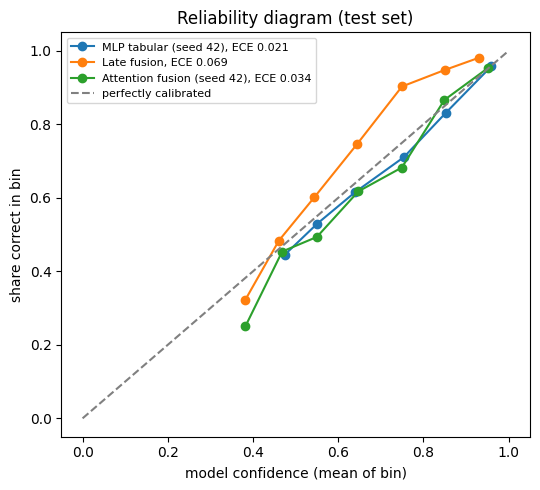

In [ ]:
# Overfitting check (Week 7): the same score on train, validation and test.
# A big drop from train to validation means the model memorised the training
# listings. Validation is a little optimistic for anything tuned on it (early
# stopping, the C grid, the late fusion weights), so test is the honest number.
fit_rows = []
for name, key in {**single, **{f"{n} (seed 42)": f"{k}_seed42" for n, k in neural.items()}}.items():
    prob = load_pred(key)
    row = {"model": name}
    for part_name, part in [("train", tr), ("val", va), ("test", te)]:
        row[part_name] = f1_score(y[part], prob[part].argmax(1), average="macro")
    row["train - val gap"] = row["train"] - row["val"]
    row["val - test gap"] = row["val"] - row["test"]
    fit_rows.append(row)
fit_table = pd.DataFrame(fit_rows).set_index("model")
print("Macro F1 on each split")
print(fit_table.round(3).to_string())

# Reliability diagram: if the model says "70% sure", is it right 70% of the time?
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5.5, 5))
edges_conf = np.linspace(0, 1, 11)
for name, key in [("MLP tabular (seed 42)", "mlp_tabular_seed42"),
                  ("Late fusion", "late_fusion_weighted"),
                  ("Attention fusion (seed 42)", "attention_fusion_seed42")]:
    p = load_pred(key)[te]
    conf, hit = p.max(1), p.argmax(1) == y[te]
    xs_plot, ys_plot = [], []
    for lo, hi in zip(edges_conf[:-1], edges_conf[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.sum() >= 20:   # skip bins too small to trust
            xs_plot.append(conf[in_bin].mean())
            ys_plot.append(hit[in_bin].mean())
    ax.plot(xs_plot, ys_plot, marker="o", label=f"{name}, ECE {ece(y[te], p):.3f}")
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="perfectly calibrated")
ax.set_xlabel("model confidence (mean of bin)")
ax.set_ylabel("share correct in bin")
ax.set_title("Reliability diagram (test set)")
ax.legend(fontsize=8)
plt.tight_layout()
try:
    fit_table.to_csv(RESULTS_DIR / "fit_by_split.csv")
    plt.savefig(FIG_DIR / "reliability_diagram.png", dpi=150)
except OSError as e:
    print(f"Couldn't save the overfitting outputs: {e}")
plt.show()

## Is the fusion gain real?

A paired bootstrap: I resample the test listings 2,000 times and recompute the macro F1 difference between two models each time. If the 95% interval doesn't include 0, the difference is unlikely to be luck. Both sides use seed 42, so each is one real trained model. Then I check the success criterion from our proposal: the best fusion model should beat the best single-modality model on test macro F1. I also check whether that gain is bigger than the bootstrap noise.

In [ ]:
# Is the fusion gain real? Paired bootstrap on the test set (resample the test
# listings 2,000 times and recompute the macro F1 difference each time)
rng = np.random.default_rng(42)
test_idx = np.where(te)[0]


def boot_diff(prob_a, prob_b, n=2000):
    pa, pb, yt = prob_a[test_idx].argmax(1), prob_b[test_idx].argmax(1), y[test_idx]
    diffs = []
    for _ in range(n):
        s = rng.integers(0, len(test_idx), len(test_idx))
        diffs.append(f1_score(yt[s], pa[s], average="macro") - f1_score(yt[s], pb[s], average="macro"))
    diffs = np.array(diffs)
    return diffs.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


# seed 42 of each neural model, so both sides are one real trained model
comparisons = [
    ("Attention fusion vs MLP tabular", "attention_fusion_seed42", "mlp_tabular_seed42"),
    ("Concat fusion vs MLP tabular", "concat_fusion_seed42", "mlp_tabular_seed42"),
    ("Attention vs concat fusion", "attention_fusion_seed42", "concat_fusion_seed42"),
    ("Late fusion vs LR tabular", "late_fusion_weighted", "lr_tabular"),
    ("Early fusion vs LR tabular", "early_fusion_lr", "lr_tabular"),
]
boot = []
for label, a, b in comparisons:
    mean, lo, hi = boot_diff(load_pred(a), load_pred(b))
    boot.append({"comparison": label, "macro F1 difference": mean, "95% CI low": lo,
                 "95% CI high": hi, "clearly better": lo > 0})
boot = pd.DataFrame(boot).set_index("comparison")
print(boot.round(3).to_string())

# the success criterion from our proposal: best fusion beats the best single
# modality on test macro F1
best_single = test_table.loc[["LR tabular", "LR text (TF-IDF)", "LR image", "Gradient boosting tabular",
                              "MLP tabular", "MLP text", "MLP image"], "macro F1"]
best_fusion = test_table.loc[["Early fusion LR", "Late fusion (weighted)", "Concat fusion",
                              "Attention fusion"], "macro F1"]
print(f"\nBest single modality: {best_single.idxmax()} ({best_single.max():.3f})")
print(f"Best fusion: {best_fusion.idxmax()} ({best_fusion.max():.3f})")
gain = best_fusion.max() - best_single.max()
print(f"Gain of best fusion over best single modality: {gain * 100:+.1f} macro F1 points")
print("Proposal success criterion (best fusion beats best single modality on test macro F1):",
      "met on the point estimate" if gain > 0 else "not met")
print("But every bootstrap interval above includes 0, so the gain is within noise: "
      "no fusion model is clearly better than its single-modality baseline.")
try:
    boot.to_csv(RESULTS_DIR / "test_bootstrap.csv")
except OSError as e:
    print(f"Couldn't save the bootstrap table: {e}")

                                 macro F1 difference  95% CI low  95% CI high  clearly better
comparison                                                                                   
Attention fusion vs MLP tabular               -0.001      -0.015        0.014           False
Concat fusion vs MLP tabular                  -0.000      -0.015        0.014           False
Attention vs concat fusion                    -0.001      -0.012        0.010           False
Late fusion vs LR tabular                      0.007      -0.005        0.019           False
Early fusion vs LR tabular                    -0.010      -0.026        0.008           False

Best single modality: MLP tabular (0.669)
Best fusion: Attention fusion (0.671)
Gain of best fusion over best single modality: +0.3 macro F1 points
Proposal success criterion (best fusion beats best single modality on test macro F1): met on the point estimate
But every bootstrap interval above includes 0, so the gain is within noise: no fu

## Confusion matrices

Each row is a true price level and shows where those listings ended up, as a share of that row.

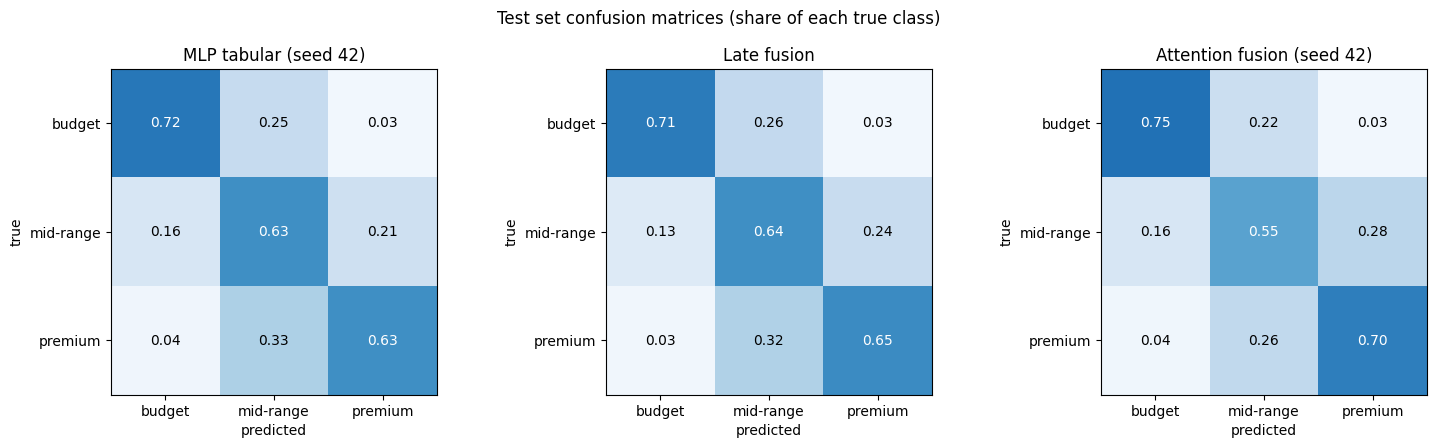

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Row-normalised confusion matrices: each row is a true price level and shows
# where those listings ended up
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (title, key) in zip(axes, [("MLP tabular (seed 42)", "mlp_tabular_seed42"),
                                   ("Late fusion", "late_fusion_weighted"),
                                   ("Attention fusion (seed 42)", "attention_fusion_seed42")]):
    cm = confusion_matrix(y[te], load_pred(key)[te].argmax(1), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3), CLASSES)
    ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
plt.suptitle("Test set confusion matrices (share of each true class)")
plt.tight_layout()
try:
    plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=150)
except OSError as e:
    print(f"Couldn't save the figure: {e}")
plt.show()

## Robustness and modality dominance

The Week 6 checks: how much does each fusion model rely on each modality? I re-score the saved models on the test set with the image removed, the text removed, both removed, the image or text swapped between random listings (so it no longer matches the listing), and Gaussian noise added to the image features. If removing or swapping a modality barely changes the score, the model wasn't really using it.

In [ ]:
MODS = ["tabular", "text", "image"]
inputs = {"tabular": X_tab, "text": X_text, "image": X_img}
present = np.stack([np.ones(len(y), bool), has_text, has_photo], axis=1)


class FusionNet(nn.Module):
    # same network as notebook 04, needed to load the saved weights
    def __init__(self, dims, mode, d=128, p_drop=0.3):
        super().__init__()
        self.mods, self.mode = list(dims), mode
        self.proj = nn.ModuleDict({m: nn.Sequential(nn.Linear(dims[m], d), nn.ReLU(),
                                                    nn.Dropout(p_drop)) for m in dims})
        if mode == "attention":
            self.score = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 1))
            head_in = d
        else:
            head_in = d * len(dims)
        self.head = nn.Sequential(nn.Linear(head_in, 64), nn.ReLU(), nn.Dropout(p_drop),
                                  nn.Linear(64, 3))

    def forward(self, xs, mask):
        z = torch.stack([self.proj[m](xs[m]) for m in self.mods], dim=1)
        z = z * mask.unsqueeze(-1)
        if self.mode == "attention":
            s = self.score(z).squeeze(-1).masked_fill(mask == 0, -1e9)
            weights = torch.softmax(s, dim=1)
            return self.head((weights.unsqueeze(-1) * z).sum(1)), weights
        return self.head(z.flatten(1)), None


def load_net(key, mods, mode):
    model = FusionNet({m: inputs[m].shape[1] for m in mods}, mode,
                      d=settings["projection_size"], p_drop=settings["dropout"]).to(device)
    try:
        model.load_state_dict(torch.load(MODEL_DIR / f"{key}.pt", map_location=device))
    except OSError as e:
        raise RuntimeError(f"Couldn't load {key}: {e}")
    return model.eval()


@torch.no_grad()
def run(model, rows, xs_np, mask_np, mods=MODS):
    xs = {m: torch.tensor(xs_np[m], device=device) for m in mods}
    mask = torch.tensor(mask_np, dtype=torch.float32, device=device)
    logits, _ = model(xs, mask)
    return torch.softmax(logits, 1).cpu().numpy()


# Robustness and dominance checks (Week 6): what happens to the fusion models
# when a modality is removed, swapped between listings, or made noisy
test_rows = np.where(te)[0]
rng = np.random.default_rng(0)
shuffle = rng.permutation(len(test_rows))   # same shuffle for every model and seed


def scenarios():
    base = {m: inputs[m][test_rows] for m in MODS}
    mask = present[test_rows].copy()
    yield "all modalities", base, mask
    for i, m in [(2, "image"), (1, "text")]:
        m2 = mask.copy()
        m2[:, i] = 0
        yield f"no {m}", base, m2
    m3 = mask.copy()
    m3[:, 1:] = 0
    yield "tabular only (no text, no image)", base, m3
    for i, m in [(2, "image"), (1, "text")]:
        # give every listing another listing's photo (or text); its mask moves with it
        swapped, m4 = dict(base), mask.copy()
        swapped[m] = base[m][shuffle]
        m4[:, i] = mask[shuffle, i]
        yield f"{m} shuffled between listings", swapped, m4
    noisy = dict(base)
    noisy["image"] = base["image"] + rng.normal(0, 1, base["image"].shape).astype(np.float32)
    yield "image + Gaussian noise (sd 1)", noisy, mask


robust = []
for name, key, mode in [("Concat fusion", "concat_fusion", "concat"),
                        ("Attention fusion", "attention_fusion", "attention")]:
    for seed in SEEDS:
        model = load_net(f"{key}_seed{seed}", MODS, mode)
        for scen, xs_np, mask_np in scenarios():
            prob = run(model, test_rows, xs_np, mask_np)
            robust.append({"model": name, "seed": seed, "scenario": scen,
                           "macro F1": f1_score(y[test_rows], prob.argmax(1), average="macro")})
robust = pd.DataFrame(robust)
robust_table = robust.pivot_table(index="scenario", columns="model", values="macro F1",
                                  aggfunc=["mean", "std"], sort=False)
print(robust_table.round(3).to_string())
try:
    robust.to_csv(RESULTS_DIR / "test_robustness.csv", index=False)
except OSError as e:
    print(f"Couldn't save the robustness table: {e}")

                                          mean                            std                 
model                            Concat fusion Attention fusion Concat fusion Attention fusion
scenario                                                                                      
all modalities                           0.669            0.671         0.007            0.004
no image                                 0.666            0.670         0.004            0.003
no text                                  0.662            0.669         0.003            0.001
tabular only (no text, no image)         0.659            0.665         0.001            0.004
image shuffled between listings          0.645            0.664         0.003            0.006
text shuffled between listings           0.651            0.644         0.002            0.006
image + Gaussian noise (sd 1)            0.668            0.670         0.007            0.002


## Modality dominance: CKA and attention weights

The second dominance check from Week 6. Linear CKA (Kornblith et al., 2019) measures how much the fused representation looks like each modality's own projection. If it's close to the tabular one and far from the image one, the model is mostly a tabular model. The figure shows the robustness results above.

Linear CKA between the fused representation and each modality (2,791 test listings with all three modalities, 3 seeds)
                 CKA with tabular        CKA with text        CKA with image       
                             mean    std          mean    std           mean    std
model                                                                              
Attention fusion            0.849  0.014         0.319  0.007          0.158  0.036
Concat fusion               0.846  0.034         0.222  0.054          0.265  0.020

Attention weights on the test set, mean over listings (sd over seeds): tabular 0.609 (0.018), text 0.321 (0.012), image 0.070 (0.006)


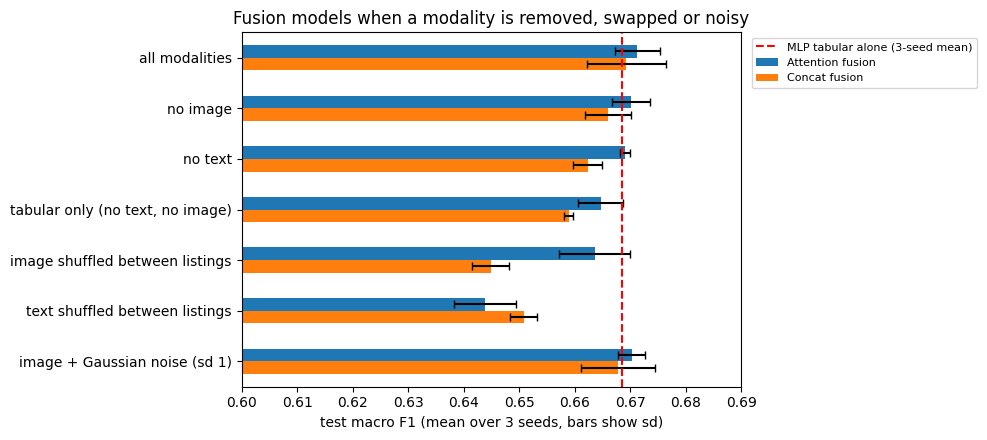

In [ ]:
# Modality dominance, second check (Week 6): how similar is the fused
# representation to each modality's own projection? Linear CKA is 1 when two
# representations carry the same information (up to rotation and scale) and near 0
# when they're unrelated. "Fused" here is the hidden layer of the classifier head,
# the last thing the model sees before it decides.
def linear_cka(a, b):
    a = a - a.mean(0)
    b = b - b.mean(0)
    return np.linalg.norm(b.T @ a) ** 2 / (np.linalg.norm(a.T @ a) * np.linalg.norm(b.T @ b))


@torch.no_grad()
def hidden_reps(model, rows):
    xs = {m: torch.tensor(inputs[m][rows], device=device) for m in model.mods}
    mask = torch.tensor(present[rows], dtype=torch.float32, device=device)
    z = torch.stack([model.proj[m](xs[m]) for m in model.mods], dim=1) * mask.unsqueeze(-1)
    if model.mode == "attention":
        s = model.score(z).squeeze(-1).masked_fill(mask == 0, -1e9)
        weights = torch.softmax(s, dim=1)
        head_in = (weights.unsqueeze(-1) * z).sum(1)
    else:
        weights, head_in = None, z.flatten(1)
    fused = model.head[:2](head_in)   # Linear + ReLU of the head, 64 numbers per listing
    per_mod = {m: z[:, i].cpu().numpy() for i, m in enumerate(model.mods)}
    return per_mod, fused.cpu().numpy(), (weights.cpu().numpy() if weights is not None else None)


# only test listings that have all three modalities, so no projection is all zeros
full_rows = test_rows[present[test_rows].all(1)]
cka_rows, test_weights = [], []
for name, key, mode in [("Concat fusion", "concat_fusion", "concat"),
                        ("Attention fusion", "attention_fusion", "attention")]:
    for seed in SEEDS:
        per_mod, fused, weights = hidden_reps(load_net(f"{key}_seed{seed}", MODS, mode), full_rows)
        cka_rows.append({"model": name, "seed": seed,
                         **{f"CKA with {m}": linear_cka(fused, per_mod[m]) for m in MODS}})
        if weights is not None:
            test_weights.append(weights.mean(0))
cka = pd.DataFrame(cka_rows).groupby("model").agg(["mean", "std"]).drop(columns="seed")
print(f"Linear CKA between the fused representation and each modality "
      f"({len(full_rows):,} test listings with all three modalities, 3 seeds)")
print(cka.round(3).to_string())
w = np.array(test_weights)
print("\nAttention weights on the test set, mean over listings (sd over seeds): " +
      ", ".join(f"{m} {w[:, i].mean():.3f} ({w[:, i].std():.3f})" for i, m in enumerate(MODS)))

# robustness figure for the report and slides
order = list(robust["scenario"].unique())
means = robust.groupby(["scenario", "model"])["macro F1"].mean().unstack().reindex(order)
sds = robust.groupby(["scenario", "model"])["macro F1"].std().unstack().reindex(order)
fig, ax = plt.subplots(figsize=(10, 4.5))
means.plot.barh(xerr=sds, ax=ax, capsize=3)
ax.axvline(test_table.loc["MLP tabular", "macro F1"], ls="--", c="red",
           label="MLP tabular alone (3-seed mean)")
ax.set_xlim(0.60, 0.69)
ax.invert_yaxis()
ax.set_xlabel("test macro F1 (mean over 3 seeds, bars show sd)")
ax.set_ylabel("")
ax.set_title("Fusion models when a modality is removed, swapped or noisy")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
try:
    cka.to_csv(RESULTS_DIR / "test_cka.csv")
    plt.savefig(FIG_DIR / "robustness.png", dpi=150)
except OSError as e:
    print(f"Couldn't save the dominance outputs: {e}")
plt.show()

## Uncertainty with MC dropout

From Week 5: keep dropout switched on at test time and run the attention model 32 times. The average gives the prediction, and the entropy of that average shows how unsure the model is. If wrong predictions have higher entropy, the uncertainty is useful: the model could pass its least certain listings to a person instead of guessing.

In [ ]:
# MC dropout (Week 5): keep dropout switched on at test time and run 32 passes.
# The spread between passes shows how unsure the model is about a listing.
def mc_dropout(model, rows, passes=32, seed=42):
    torch.manual_seed(seed)   # fixed seed so the dropout masks, and the results, are the same every run
    model.eval()
    for layer in model.modules():
        if isinstance(layer, nn.Dropout):
            layer.train()   # only dropout is random, everything else stays in eval mode
    xs = {m: inputs[m][rows] for m in MODS}
    probs = np.stack([run(model, rows, xs, present[rows]) for _ in range(passes)])
    model.eval()
    return probs.mean(0), probs.std(0).mean(1)


model = load_net("attention_fusion_seed42", MODS, "attention")
mc_mean, mc_spread = mc_dropout(model, test_rows)
entropy = -(mc_mean * np.log(mc_mean + 1e-12)).sum(1)   # high = unsure
correct = mc_mean.argmax(1) == y[test_rows]
print(f"MC dropout macro F1: {f1_score(y[test_rows], mc_mean.argmax(1), average='macro'):.3f}")
print(f"Mean entropy, correct predictions: {entropy[correct].mean():.3f}; "
      f"wrong predictions: {entropy[~correct].mean():.3f}")

# if the model only answered for the listings it's most sure about, how accurate is it?
order = np.argsort(entropy)
coverage_rows = []
for keep in [1.0, 0.8, 0.6, 0.4]:
    kept = order[:int(keep * len(order))]
    coverage_rows.append({"share of listings answered": keep,
                          "accuracy": correct[kept].mean(),
                          "macro F1": f1_score(y[test_rows][kept], mc_mean[kept].argmax(1), average="macro")})
coverage = pd.DataFrame(coverage_rows)
print(coverage.round(3).to_string(index=False))
try:
    coverage.to_csv(RESULTS_DIR / "test_uncertainty_coverage.csv", index=False)
except OSError as e:
    print(f"Couldn't save the uncertainty table: {e}")

MC dropout macro F1: 0.672
Mean entropy, correct predictions: 0.664; wrong predictions: 0.865
 share of listings answered  accuracy  macro F1
                        1.0     0.669     0.672
                        0.8     0.718     0.709
                        0.6     0.776     0.725
                        0.4     0.861     0.683


## Fairness across areas

Premium share really differs by area (18% to 58% in the initial analysis), so equal "premium" rates everywhere isn't the goal. Instead I compare areas with at least 50 test listings on: error rate (error-rate parity), recall of premium listings (equal opportunity), and bias amplification (Zhao et al., 2017), which asks whether the model exaggerates the real differences between areas. If predicted premium share rises faster than true premium share across areas (a slope above 1), the model is widening the gaps. Sasha suggested checking these for the single-modality models and then again after fusion, so I compare both.

16 areas with at least 50 test listings, covering 84.6% of the test set
                  macro F1  error rate gap (max - min)  premium recall gap (max - min)  amplification slope
model                                                                                                      
MLP tabular          0.668                       0.287                           0.402                0.807
MLP text             0.585                       0.317                           0.644                0.971
MLP image            0.507                       0.265                           0.322                0.606
Late fusion          0.671                       0.308                           0.504                0.808
Attention fusion     0.667                       0.313                           0.446                0.945

Attention fusion by area (seed 42):
              listings  true premium share  predicted premium share  error rate  premium recall
area                                   

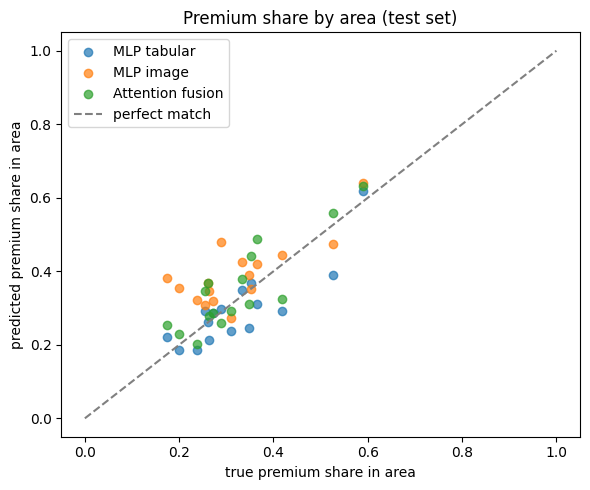

In [ ]:
# Fairness across areas (Week 7). Areas really do differ in how many premium
# listings they have, so equal "premium" rates aren't the goal. Instead I check:
#  - error rate per area (error-rate parity)
#  - recall of premium listings per area (equal opportunity)
#  - bias amplification (Zhao et al., 2017): across areas, does the predicted premium
#    share exaggerate the true one? A slope above 1 means the model widens the gaps.
area = df["neighbourhood_cleansed"].fillna("unknown").to_numpy()
test_area = pd.Series(area[te])
big_areas = test_area.value_counts()[lambda s: s >= 50].index
print(f"{len(big_areas)} areas with at least 50 test listings, "
      f"covering {test_area.isin(big_areas).mean():.1%} of the test set")


def area_report(prob):
    pred, yt = prob[te].argmax(1), y[te]
    out = []
    for a in big_areas:
        m = (test_area == a).to_numpy()
        prem = m & (yt == 2)
        out.append({"area": a, "listings": m.sum(), "true premium share": (yt[m] == 2).mean(),
                    "predicted premium share": (pred[m] == 2).mean(),
                    "error rate": (pred[m] != yt[m]).mean(),
                    "premium recall": (pred[prem] == 2).mean() if prem.any() else np.nan})
    return pd.DataFrame(out).set_index("area")


def fairness_summary(name, prob):
    r = area_report(prob)
    slope = np.polyfit(r["true premium share"], r["predicted premium share"], 1)[0]
    return {"model": name, "macro F1": f1_score(y[te], prob[te].argmax(1), average="macro"),
            "error rate gap (max - min)": r["error rate"].max() - r["error rate"].min(),
            "premium recall gap (max - min)": r["premium recall"].max() - r["premium recall"].min(),
            "amplification slope": slope}


fair_models = {"MLP tabular": "mlp_tabular_seed42", "MLP text": "mlp_text_seed42",
               "MLP image": "mlp_image_seed42", "Late fusion": "late_fusion_weighted",
               "Attention fusion": "attention_fusion_seed42"}
fairness = pd.DataFrame([fairness_summary(n, load_pred(k)) for n, k in fair_models.items()]).set_index("model")
print(fairness.round(3).to_string())

per_area = area_report(load_pred("attention_fusion_seed42")).sort_values("true premium share")
print("\nAttention fusion by area (seed 42):")
print(per_area.round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 5))
for name in ["MLP tabular", "MLP image", "Attention fusion"]:
    r = area_report(load_pred(fair_models[name]))
    ax.scatter(r["true premium share"], r["predicted premium share"], label=name, alpha=0.7)
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="perfect match")
ax.set_xlabel("true premium share in area")
ax.set_ylabel("predicted premium share in area")
ax.set_title("Premium share by area (test set)")
ax.legend()
plt.tight_layout()
try:
    plt.savefig(FIG_DIR / "area_premium_share.png", dpi=150)
    fairness.to_csv(RESULTS_DIR / "test_fairness.csv")
    per_area.to_csv(RESULTS_DIR / "test_fairness_by_area.csv")
except OSError as e:
    print(f"Couldn't save the fairness outputs: {e}")
plt.show()

## Mitigation: training without the area features

One obvious way to reduce area bias is to take the area columns out of the tabular features. I retrain the tabular MLP and the attention fusion model without them (same settings and seeds as notebook 04) and compare accuracy and the area gaps. This shows what the mitigation costs and whether it actually helps, since location can still leak in through the photo or the description.

In [ ]:
# Mitigation test: take the area columns out of the tabular features and retrain,
# to see what it costs in accuracy and whether the area gaps shrink.
# The area one-hot columns are the 0/1 columns that vary overall but never change
# within an area (rare areas share one "infrequent" column, so the count can be
# a little lower than the number of areas).
area_cols = [j for j in range(X_tab.shape[1])
             if X_tab[:, j].std() > 0
             and np.isin(np.unique(X_tab[:, j]), [0, 1]).all()
             and pd.Series(X_tab[:, j]).groupby(area).nunique().max() == 1]
print(f"Found {len(area_cols)} area columns out of {X_tab.shape[1]} tabular columns "
      f"({len(set(area))} areas in the data)")
keep_cols = [j for j in range(X_tab.shape[1]) if j not in area_cols]
inputs_no_area = {"tabular": X_tab[:, keep_cols], "text": X_text, "image": X_img}


def train_quick(mods, mode, seed, feats, p_mod_drop=0.2, max_epochs=60, patience=6, batch=256):
    # same training as notebook 04 (Adam, early stopping on validation loss)
    torch.manual_seed(seed)
    model = FusionNet({m: feats[m].shape[1] for m in mods}, mode, d=settings["projection_size"],
                      p_drop=settings["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"],
                           weight_decay=settings["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    cols = [MODS.index(m) for m in mods]

    def tensors(rows):
        return ({m: torch.tensor(feats[m][rows], device=device) for m in mods},
                torch.tensor(present[rows][:, cols], dtype=torch.float32, device=device),
                torch.tensor(y[rows], dtype=torch.long, device=device))

    xs_tr, mask_tr, y_tr = tensors(np.where(tr)[0])
    xs_va, mask_va, y_va = tensors(np.where(va)[0])
    droppable = [i for i, m in enumerate(mods) if m != "tabular"]
    best, wait = None, 0
    for epoch in range(max_epochs):
        model.train()
        order = torch.randperm(len(y_tr), device=device)
        for i in range(0, len(order), batch):
            idx = order[i:i + batch]
            mask = mask_tr[idx].clone()
            if p_mod_drop > 0 and droppable:
                drop = torch.rand(len(idx), len(droppable), device=device) < p_mod_drop
                mask[:, droppable] *= (~drop).float()
            loss = loss_fn(model({m: xs_tr[m][idx] for m in mods}, mask)[0], y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(xs_va, mask_va)[0], y_va).item()
        if best is None or val_loss < best[0]:
            best, wait = (val_loss, {k: v.clone() for k, v in model.state_dict().items()}), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best[1])
    model.eval()
    with torch.no_grad():
        xs_all = {m: torch.tensor(feats[m], device=device) for m in mods}
        mask_all = torch.tensor(present[:, cols], dtype=torch.float32, device=device)
        return torch.softmax(model(xs_all, mask_all)[0], 1).cpu().numpy()


mitigation = []
for seed in SEEDS:
    for name, mods, mode in [("MLP tabular", ["tabular"], "concat"),
                             ("Attention fusion", MODS, "attention")]:
        for with_area in [True, False]:
            f = inputs if with_area else inputs_no_area
            p_mod = 0.0 if mods == ["tabular"] else 0.2
            prob = (load_pred(f"{name.lower().replace(' ', '_')}_seed{seed}") if with_area
                    else train_quick(mods, mode, seed, f, p_mod_drop=p_mod))
            mitigation.append({**fairness_summary(name, prob), "area features": with_area, "seed": seed})
mitigation = pd.DataFrame(mitigation)
mit_table = mitigation.groupby(["model", "area features"]).mean(numeric_only=True).drop(columns="seed")
print(mit_table.round(3).to_string())
try:
    mitigation.to_csv(RESULTS_DIR / "test_mitigation_no_area.csv", index=False)
except OSError as e:
    print(f"Couldn't save the mitigation table: {e}")

Found 30 area columns out of 62 tabular columns (30 areas in the data)
                                macro F1  error rate gap (max - min)  premium recall gap (max - min)  amplification slope
model            area features                                                                                           
Attention fusion False             0.677                       0.305                           0.523                0.783
                 True              0.671                       0.302                           0.465                0.914
MLP tabular      False             0.661                       0.304                           0.479                0.596
                 True              0.669                       0.281                           0.384                0.825


## Efficiency

What it costs to score one new listing (Week 6 and 7): model size, training time, model inference time per listing, and the time to turn a photo and description into features. The photo and BERT timings come from notebook 03; TF-IDF + SVD is timed here.

In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

# Efficiency (Week 6 and 7): what it costs to score one new listing
try:
    feat_time = pd.read_csv(RESULTS_DIR / "feature_timing.csv", index_col=0)["ms_per_item"]
    val_neural = pd.read_csv(RESULTS_DIR / "val_neural_summary.csv", index_col=0)
except OSError as e:
    raise RuntimeError(f"Run notebooks 03 and 04 first: {e}")

# TF-IDF + SVD isn't timed anywhere else, so refit it the same way and time the transform
texts = df["description_clean"].fillna("")
t0 = time.time()
tfidf = TfidfVectorizer(min_df=5, max_features=20000, ngram_range=(1, 2)).fit(texts[tr])
svd = TruncatedSVD(n_components=settings["text_dims"], random_state=42).fit(tfidf.transform(texts[tr]))
fit_s = time.time() - t0
t0 = time.time()
svd.transform(tfidf.transform(texts[te]))
text_ms = 1000 * (time.time() - t0) / te.sum()

eff = []
for name, key, mode, mods in [("MLP tabular", "mlp_tabular_seed42", "concat", ["tabular"]),
                              ("Concat fusion", "concat_fusion_seed42", "concat", MODS),
                              ("Attention fusion", "attention_fusion_seed42", "attention", MODS)]:
    model = load_net(key, mods, mode)
    xs = {m: inputs[m][test_rows] for m in mods}
    mask = present[test_rows][:, [MODS.index(m) for m in mods]]
    run(model, test_rows, xs, mask, mods)   # warm-up run
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
        base = torch.cuda.memory_allocated()
    t0 = time.time()
    for _ in range(20):
        run(model, test_rows, xs, mask, mods)
    infer_ms = 1000 * (time.time() - t0) / 20 / len(test_rows)
    extra_mb = (torch.cuda.max_memory_allocated() - base) / 1e6 if device == "cuda" else float("nan")
    n_params = int(val_neural.loc[name, "params"])
    eff.append({"model": name, "parameters": n_params,
                "size (MB, float32)": n_params * 4 / 1e6,
                "training time (s)": val_neural.loc[name, "train_s"],
                "model inference (ms per listing)": infer_ms,
                "extra GPU memory to score the test set (MB)": extra_mb})
eff = pd.DataFrame(eff).set_index("model")
print(eff.round(4).to_string())
print(f"\nFeature extraction per listing: EfficientNet-B0 photo {feat_time['image_effnet_crop']:.2f} ms (GPU), "
      f"TF-IDF + SVD text {text_ms:.3f} ms (CPU), BERT text if used {feat_time['text_bert']:.2f} ms (GPU)")
print(f"Fitting TF-IDF + SVD on the training set took {fit_s:.0f} s")
try:
    eff.to_csv(RESULTS_DIR / "test_efficiency.csv")
except OSError as e:
    print(f"Couldn't save the efficiency table: {e}")

                  parameters  size (MB, float32)  training time (s)  model inference (ms per listing)  extra GPU memory to score the test set (MB)
model                                                                                                                                             
MLP tabular            16515              0.0661             2.0363                            0.0003                                       4.6459
Concat fusion         235395              0.9416             1.3467                            0.0019                                      28.3500
Attention fusion      227332              0.9093             2.1785                            0.0019                                      29.0591

Feature extraction per listing: EfficientNet-B0 photo 1.32 ms (GPU), TF-IDF + SVD text 0.109 ms (CPU), BERT text if used 8.82 ms (GPU)
Fitting TF-IDF + SVD on the training set took 11 s


## Failure cases

Where does the attention model go wrong? First, error rate by nightly price, to see whether mistakes pile up near the "$200 " and "$323" cut-offs, where a few dollars flip the label. Then the most confident budget-premium mix-ups, with their listing details and the start of the description. Photos aren't shown, because we said in the proposal they wouldn't be published.

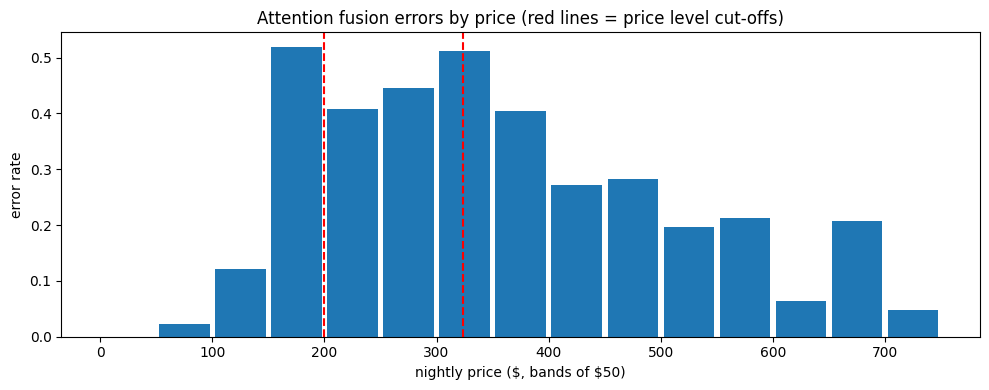

Budget-premium mix-ups: 63 of 2,830 test listings
  price    true    pred  conf       room_type                     property_type  accommodates  bedrooms neighbourhood_cleansed                                                                                                                     text
 380.00 premium  budget  0.99    Private room       Private room in rental unit             1       1.0            Stonnington 1 min to train, 1 min to tram, 1 km to chapel St. the best place for hub, cafes ... next to park 10 mins to CBD by train
 390.00 premium  budget  0.98    Private room       Private room in rental unit             1       1.0                Wyndham Private room Amenities - WiFi Close to Public Transport Queen Bed Modern Quiet Friendly, hospitibal host looking to meet
1250.00 premium  budget  0.97    Private room              Private room in home             1       0.0                 Monash                                                            it is a nice place t

In [ ]:
# Where does the best neural model go wrong? Error rate by price shows whether
# mistakes pile up near the $200 and $323 cut-offs, where a few dollars flip the label
with open(RESULTS_DIR / "target_edges.json") as f:
    edges = json.load(f)
prob = load_pred("attention_fusion_seed42")
pred = prob.argmax(1)
test_df = df[te].assign(pred=pred[te], conf=prob[te].max(1), true=y[te])
bins = np.arange(0, edges["cap"] + 50, 50)
test_df["price band"] = pd.cut(test_df["price"], bins)
err_by_price = (test_df.assign(wrong=test_df["pred"] != test_df["true"])
                .groupby("price band", observed=True)
                .agg(**{"listings": ("wrong", "size"), "error rate": ("wrong", "mean")}))
err_by_price = err_by_price[err_by_price["listings"] >= 20]   # skip bands too small to trust

# bars sit on a real dollar axis, so the cut-off lines land exactly at $200 and $323
fig, ax = plt.subplots(figsize=(10, 4))
lefts = np.array([b.left for b in err_by_price.index])
ax.bar(lefts + 25, err_by_price["error rate"], width=45)
for edge in [edges["budget_max"], edges["midrange_max"]]:
    ax.axvline(edge, ls="--", c="red")
ax.set_xlabel(r"nightly price (\$, bands of \$50)")
ax.set_ylabel("error rate")
ax.set_title("Attention fusion errors by price (red lines = price level cut-offs)")
plt.tight_layout()
try:
    plt.savefig(FIG_DIR / "errors_by_price.png", dpi=150)
except OSError as e:
    print(f"Couldn't save the figure: {e}")
plt.show()

# the most confident budget-premium mix-ups, the worst kind of error
mixups = test_df[((test_df["true"] == 0) & (test_df["pred"] == 2)) |
                 ((test_df["true"] == 2) & (test_df["pred"] == 0))]
worst = mixups.nlargest(8, "conf")
worst = worst.assign(true=worst["true"].map(dict(enumerate(CLASSES))),
                     pred=worst["pred"].map(dict(enumerate(CLASSES))),
                     text=worst["description_clean"].str[:120])
print(f"Budget-premium mix-ups: {len(mixups)} of {len(test_df):,} test listings")
print(worst[["price", "true", "pred", "conf", "room_type", "property_type", "accommodates",
             "bedrooms", "neighbourhood_cleansed", "text"]].round(2).to_string(index=False))

## Making sure everything is saved

Colab uploads to Drive in the background, so this waits until everything is actually on Drive before the runtime closes.

In [ ]:
from google.colab import drive
drive.flush_and_unmount()
print("Everything saved to Drive")

Everything saved to Drive
